Upload your KITTEN (content) image


Saving pexels-primitive-spaces-2147980412-34719941.jpg to pexels-primitive-spaces-2147980412-34719941.jpg
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:06<00:00, 92.0MB/s]


Step 50 | style 31.354 | content 17.360
Step 100 | style 5.828 | content 17.379
Step 150 | style 3.081 | content 15.613
Step 200 | style 2.274 | content 14.566
Step 250 | style 1.783 | content 13.955
Step 300 | style 1.445 | content 13.561


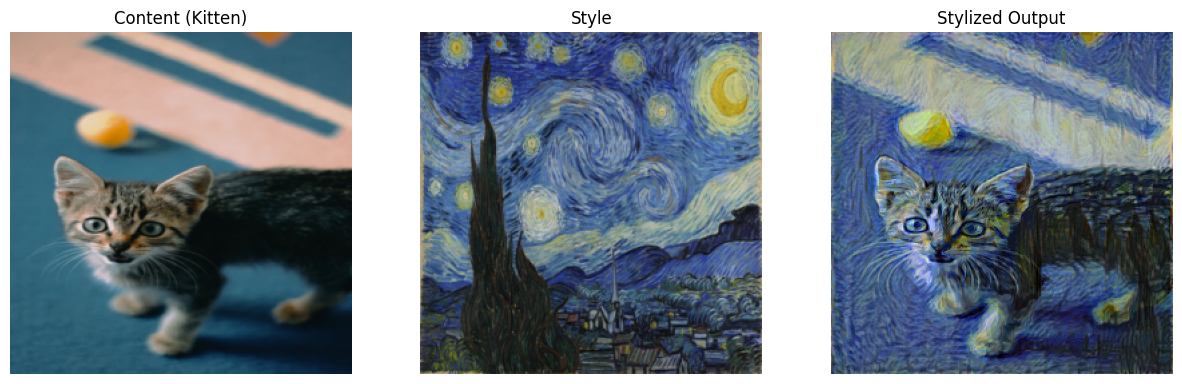

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch, torch.nn as nn, torch.optim as optim
import torchvision.transforms as T
from torchvision.models import vgg19, VGG19_Weights
from PIL import Image
import matplotlib.pyplot as plt
import urllib.request
from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
imsize = 512 if torch.cuda.is_available() else 256

# ---------- Load images ----------
print("Upload your KITTEN (content) image")
content_path = list(files.upload().keys())[0]

style_url = ("https://upload.wikimedia.org/wikipedia/commons/thumb/e/ea/"
             "Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg/"
             "1280px-Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg")
try:
    req = urllib.request.Request(style_url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r, open("style.jpg", "wb") as f:
        f.write(r.read())
    style_path = "style.jpg"
except Exception:
    print("Download failed. Upload a STYLE image")
    style_path = list(files.upload().keys())[0]

loader = T.Compose([T.Resize((imsize, imsize)), T.ToTensor()])
load = lambda p: loader(Image.open(p).convert("RGB")).unsqueeze(0).to(device)
content_img, style_img = load(content_path), load(style_path)

def show(t, title=None):
    plt.imshow(t.detach().cpu().squeeze(0).permute(1, 2, 0).clamp(0, 1))
    plt.axis("off")
    if title: plt.title(title)

# ---------- Losses ----------
def gram(x):
    b, c, h, w = x.size()
    f = x.view(b * c, h * w)
    return f @ f.t() / (b * c * h * w)

class Normalize(nn.Module):
    def __init__(self):
        super().__init__()
        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(-1, 1, 1).to(device)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(-1, 1, 1).to(device)
    def forward(self, x):
        return (x - self.mean) / self.std

class ContentLoss(nn.Module):
    def __init__(self, target):
        super().__init__()
        self.target = target.detach()
    def forward(self, x):
        self.loss = nn.functional.mse_loss(x, self.target)
        return x

class StyleLoss(nn.Module):
    def __init__(self, target):
        super().__init__()
        self.target = gram(target).detach()
    def forward(self, x):
        self.loss = nn.functional.mse_loss(gram(x), self.target)
        return x

# ---------- Model ----------
content_layers = ["conv_4"]
style_layers = ["conv_1", "conv_2", "conv_3", "conv_4", "conv_5"]

cnn = vgg19(weights=VGG19_Weights.DEFAULT).features.to(device).eval()
model = nn.Sequential(Normalize())
c_losses, s_losses = [], []
i = 0
for layer in cnn.children():
    if isinstance(layer, nn.Conv2d):
        i += 1; name = f"conv_{i}"
    elif isinstance(layer, nn.ReLU):
        name = f"relu_{i}"; layer = nn.ReLU(inplace=False)
    elif isinstance(layer, nn.MaxPool2d):
        name = f"pool_{i}"
    else:
        name = f"bn_{i}"
    model.add_module(name, layer)
    if name in content_layers:
        l = ContentLoss(model(content_img)); model.add_module(f"closs_{i}", l); c_losses.append(l)
    if name in style_layers:
        l = StyleLoss(model(style_img)); model.add_module(f"sloss_{i}", l); s_losses.append(l)

for j in range(len(model) - 1, -1, -1):
    if isinstance(model[j], (ContentLoss, StyleLoss)):
        break
model = model[: j + 1]
for p in model.parameters():
    p.requires_grad_(False)

# ---------- Optimize ----------
def run_style_transfer(steps=300, style_weight=1e6, content_weight=1):
    img = content_img.clone().requires_grad_(True)
    opt = optim.LBFGS([img])
    step = [0]
    while step[0] <= steps:
        def closure():
            with torch.no_grad():
                img.clamp_(0, 1)
            opt.zero_grad()
            model(img)
            s = style_weight * sum(l.loss for l in s_losses)
            c = content_weight * sum(l.loss for l in c_losses)
            loss = s + c
            loss.backward()
            step[0] += 1
            if step[0] % 50 == 0:
                print(f"Step {step[0]} | style {s.item():.3f} | content {c.item():.3f}")
            return loss
        opt.step(closure)
    with torch.no_grad():
        img.clamp_(0, 1)
    return img

output = run_style_transfer(steps=300)

# ---------- Show & save ----------
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); show(content_img, "Content (Kitten)")
plt.subplot(1, 3, 2); show(style_img, "Style")
plt.subplot(1, 3, 3); show(output, "Stylized Output")
plt.show()

T.ToPILImage()(output.detach().cpu().squeeze(0)).save("stylized_kitten.jpg")
files.download("stylized_kitten.jpg")